# Task 5: Clustering Analysis on Final Embeddings

This notebook evaluates KMeans clustering behavior across six embedding representations derived from the 158 clusterable constitutional preambles:
- **Variant A**: Final raw text embeddings (`emb_final_raw.npy`).
- **Variant B**: Cleaned text embeddings (`emb_final_clean.npy`).
- **Variant C**: Masked raw text embeddings (`emb_final_masked.npy`), where each country's own name and capitalized name components ($\ge 4$ characters) are replaced with `[COUNTRY]`.
- **Variants A_c, B_c, C_c**: Column-mean centered and row L2-normalized counterparts of A, B, and C.

Analyses conducted:
1. **Metrics vs $k$**: Silhouette (cosine), Davies-Bouldin, Calinski-Harabasz, and Inertia for $k \in [2, 12]$ using `n_init=50, random_state=42`, with summary tables and four-panel plots.
2. **Null Baseline**: Comparison of real clustering silhouette in 50-dimensional PCA space against 30 Gaussian null datasets matched on component mean and standard deviation.
3. **Seed Stability**: Pairwise Adjusted Rand Index (ARI) distributions across 30 random initialization seeds ($n_{	ext{init}}=10$) for $k \in [4, 10]$, plus partition identity rates at $k=7$ ($n_{	ext{init}}=50$).
4. **Subsample Stability**: Robustness under 80% subsampling without replacement across 30 draws for $k \in [5, 7, 9]$.
5. **Agreement**: $6 	imes 6$ ARI matrix between all six representations at $k=7$.
6. **Length Confound Diagnostics**: Word count distributions across clusters, Kruskal-Wallis non-parametric tests, and ARI with word-count terciles.
7. **Original Clusters Comparison**: Agreement with original 7 clusters and contingency matrix for the highest-silhouette representation.
8. **Final Cluster Export**: Persisting $k=7$ cluster assignments for all versions to `data/processed/cluster_runs.csv`.

## 1. Setup, Input Verification, and Variant C Construction
Verify input row ordering against `data/processed/preamble_final.csv`, construct Variant C (masked raw preamble text), generate embeddings using token-weighted pooling and L2 normalization, and construct the six evaluated embedding variants.

In [1]:
import os
import re
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import kruskal
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from sentence_transformers import SentenceTransformer

data_dir = '../data/processed'

# 1. Load order file and final preambles
df_order = pd.read_csv(os.path.join(data_dir, 'final_country_order.csv'))
df_final = pd.read_csv(os.path.join(data_dir, 'preamble_final.csv'))
df_clusterable = df_final[df_final['status'].isin(['preamble_ok', 'preamble_cut'])].copy().reset_index(drop=True)

# Assertions
assert len(df_order) == 158, f"Expected 158 rows in order file, got {len(df_order)}"
assert (df_order['Country'] == df_clusterable['Country']).all(), "Country alignment mismatch between order file and clusterable preambles!"
print(f"Validated input order: 158 aligned clusterable countries.")

# 2. Rebuild Variant C (Masked Raw)
def mask_country_name(country, text):
    words = re.findall(r'[a-zA-Z]+', country)
    cap_words = [w for w in words if w and w[0].isupper() and len(w) >= 4]
    terms = set([country] + cap_words)
    sorted_terms = sorted(terms, key=len, reverse=True)
    pattern = r'\b(?:' + '|'.join(re.escape(t) for t in sorted_terms) + r')\b'
    masked_text, count = re.subn(pattern, '[COUNTRY]', text, flags=re.IGNORECASE)
    return masked_text, count

mask_records = []
masked_texts = []
for idx, r in df_clusterable.iterrows():
    c = r['Country']
    raw_t = ' '.join(str(r['extracted_text']).split())
    m_t, cnt = mask_country_name(c, raw_t)
    masked_texts.append(m_t)
    mask_records.append((c, cnt))

cnt_ge1 = sum(cnt > 0 for _, cnt in mask_records)
cnt_zero = sum(cnt == 0 for _, cnt in mask_records)
print(f"Variant C Masking Statistics:")
print(f"  Countries with >= 1 replacement: {cnt_ge1}")
print(f"  Countries with 0 replacements:    {cnt_zero}")
print(f"\nTop 10 countries with most replacements:")
for c, cnt in sorted(mask_records, key=lambda x: x[1], reverse=True)[:10]:
    print(f"  {c:<25}: {cnt}")

# Check or generate emb_final_masked.npy
masked_npy_path = os.path.join(data_dir, 'emb_final_masked.npy')
if os.path.exists(masked_npy_path):
    print(f"\nLoading existing Variant C embeddings from: {masked_npy_path}")
    emb_C = np.load(masked_npy_path)
else:
    print(f"\nGenerating Variant C embeddings with all-mpnet-base-v2...")
    model = SentenceTransformer('all-mpnet-base-v2')
    tokenizer = model.tokenizer
    
    def count_tokens(text):
        return len(tokenizer.encode(str(text), add_special_tokens=False))
        
    def chunk_variant_a(text, max_tokens=300):
        text = ' '.join(str(text).split())
        tot = count_tokens(text)
        if tot <= max_tokens:
            return [text], [tot]
        raw_sents = [s.strip() for s in re.split(r'(?<=[.?!])\s+', text) if s.strip()]
        units = []
        for s in raw_sents:
            s_toks = tokenizer.encode(s, add_special_tokens=False)
            if len(s_toks) <= max_tokens:
                units.append(s)
            else:
                for j in range(0, len(s_toks), max_tokens):
                    sub_ids = s_toks[j:j+max_tokens]
                    sub_t = tokenizer.decode(sub_ids, skip_special_tokens=True).strip()
                    if sub_t: units.append(sub_t)
        chunks, curr = [], []
        for u in units:
            cand = ' '.join(curr + [u]) if curr else u
            if count_tokens(cand) <= max_tokens:
                curr.append(u)
            else:
                if curr: chunks.append(' '.join(curr))
                curr = [u]
        if curr: chunks.append(' '.join(curr))
        chunk_tokens = [count_tokens(c) for c in chunks]
        return chunks, chunk_tokens
        
    c_chunks, c_tokens = [], []
    for mt in masked_texts:
        ch, tk = chunk_variant_a(mt)
        c_chunks.append(ch)
        c_tokens.append(tk)
        
    all_chunks = []
    chunk_counts = []
    for c_list in c_chunks:
        all_chunks.extend(c_list)
        chunk_counts.append(len(c_list))
    all_embeddings = model.encode(all_chunks, batch_size=32, show_progress_bar=False, normalize_embeddings=False)
    
    country_embeddings = []
    idx = 0
    for i, count in enumerate(chunk_counts):
        c_embs = all_embeddings[idx:idx+count]
        c_weights = np.array(c_tokens[i], dtype=np.float32)
        idx += count
        weighted_mean = np.average(c_embs, axis=0, weights=c_weights)
        norm = np.linalg.norm(weighted_mean)
        l2_normed = weighted_mean / norm
        country_embeddings.append(l2_normed)
        
    emb_C = np.array(country_embeddings, dtype=np.float32)
    np.save(masked_npy_path, emb_C)

assert emb_C.shape == (158, 768), f"Expected shape (158, 768), got {emb_C.shape}"
print(f"Variant C embedding shape verified: {emb_C.shape}")

# Load Variants A and B
emb_A = np.load(os.path.join(data_dir, 'emb_final_raw.npy'))
emb_B = np.load(os.path.join(data_dir, 'emb_final_clean.npy'))

# Centered and normalized versions
def center_and_normalize(emb):
    centered = emb - emb.mean(axis=0)
    norm = np.linalg.norm(centered, axis=1, keepdims=True)
    return centered / norm

emb_A_c = center_and_normalize(emb_A)
emb_B_c = center_and_normalize(emb_B)
emb_C_c = center_and_normalize(emb_C)

versions = {
    'A': emb_A,
    'B': emb_B,
    'C': emb_C,
    'A_c': emb_A_c,
    'B_c': emb_B_c,
    'C_c': emb_C_c
}

print(f"\nInitialized all six embedding representations:")
for name, emb in versions.items():
    print(f"  Version {name:<5}: shape={emb.shape}, norm min={np.min(np.linalg.norm(emb, axis=1)):.4f}, norm max={np.max(np.linalg.norm(emb, axis=1)):.4f}")


/home/devpanchal/Projects/PreambleMap/venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Validated input order: 158 aligned clusterable countries.
Variant C Masking Statistics:
  Countries with >= 1 replacement: 131
  Countries with 0 replacements:    27

Top 10 countries with most replacements:
  China                    : 23
  Tuvalu                   : 20
  Croatia                  : 15
  Papua New Guinea         : 14
  United Arab Emirates     : 10
  Iran                     : 9
  Pakistan                 : 9
  Indonesia                : 8
  North Macedonia          : 8
  Algeria                  : 7

Loading existing Variant C embeddings from: ../data/processed/emb_final_masked.npy
Variant C embedding shape verified: (158, 768)

Initialized all six embedding representations:
  Version A    : shape=(158, 768), norm min=1.0000, norm max=1.0000
  Version B    : shape=(158, 768), norm min=1.0000, norm max=1.0000
  Version C    : shape=(158, 768), norm min=1.0000, norm max=1.0000
  Version A_c  : shape=(158, 768), norm min=1.0000, norm max=1.0000
  Version B_c  : shape=(15

## 2. Clustering Metrics vs. $k$ ($k \in [2, 12]$)
Run KMeans clustering with $n_{	ext{init}}=50$ and `random_state=42` for each value of $k \in [2, 12]$ across all six representations. Evaluate Silhouette (cosine distance), Davies-Bouldin, Calinski-Harabasz, and Inertia, and generate metric-by-$k$ tables and visualization panels.

=== SILHOUETTE SCORE (COSINE) ===


,2,3,4,5,6,7,8,9,10,11,12
A,0.0956,0.1063,0.1228,0.1416,0.1453,0.1470,0.1277,0.1219,0.1280,0.1210,0.1183
B,0.0865,0.1159,0.1207,0.1437,0.1375,0.1411,0.1394,0.1402,0.1247,0.1365,0.1247
C,0.0966,0.1117,0.1222,0.1282,0.1343,0.1267,0.1293,0.1184,0.1176,0.0954,0.1268
A_c,0.1055,0.1229,0.1308,0.1413,0.1465,0.1379,0.1414,0.1410,0.1333,0.1351,0.1281
B_c,0.1096,0.1153,0.1327,0.1460,0.1463,0.1471,0.1393,0.1391,0.1329,0.1345,0.1420
C_c,0.1066,0.1117,0.1278,0.1388,0.1515,0.1604,0.1535,0.1486,0.1342,0.1369,0.1306



=== DAVIES-BOULDIN SCORE ===


,2,3,4,5,6,7,8,9,10,11,12
A,3.8775,3.4478,3.1606,2.9791,2.8688,2.7066,2.7048,2.8015,2.6689,2.5731,2.6178
B,3.2143,3.3146,3.2134,2.9035,2.8249,2.8366,2.7452,2.6348,2.8101,2.6078,2.6886
C,3.7357,3.4291,2.9907,2.8290,2.5925,2.5767,2.5616,2.5628,2.5197,2.5346,2.2512
A_c,3.4459,3.4263,3.0245,2.9601,2.8106,2.7824,2.7133,2.6439,2.6691,2.5910,2.6139
B_c,3.2141,3.5899,3.1905,2.8964,2.8150,2.5951,2.6974,2.7574,2.7433,2.7162,2.5125
C_c,3.6484,3.4573,3.0557,2.7814,2.6688,2.6156,2.5843,2.4170,2.5926,2.4868,2.5792



=== CALINSKI-HARABASZ SCORE ===


,2,3,4,5,6,7,8,9,10,11,12
A,10.07,9.63,8.63,8.26,7.82,7.31,6.93,6.36,6.17,5.84,5.52
B,10.48,9.39,8.86,8.45,7.64,7.20,6.74,6.48,6.01,5.84,5.54
C,9.60,9.18,8.99,8.67,8.38,7.70,7.26,6.95,6.45,5.96,5.88
A_c,10.62,9.97,8.87,8.38,7.92,7.45,7.07,6.68,6.30,5.91,5.67
B_c,11.02,9.58,9.01,8.48,7.85,7.35,6.92,6.39,6.04,5.88,5.63
C_c,10.65,9.70,9.16,8.89,8.51,8.09,7.54,7.16,6.65,6.27,5.95



=== INERTIA ===


,2,3,4,5,6,7,8,9,10,11,12
A,72.58,68.73,66.15,63.54,61.45,59.87,58.37,57.60,56.19,55.29,54.56
B,74.05,70.49,67.39,64.73,63.15,61.45,60.12,58.62,57.89,56.57,55.75
C,61.08,57.97,55.18,52.85,50.83,49.64,48.42,47.22,46.57,46.13,44.93
A_c,147.90,139.96,134.69,129.57,125.32,121.89,118.78,116.28,114.23,112.69,110.71
B_c,147.53,140.58,134.36,129.28,125.55,122.23,119.39,117.62,115.51,112.81,110.93
C_c,147.72,140.26,133.91,128.06,123.28,119.41,116.75,113.98,112.37,110.64,108.98


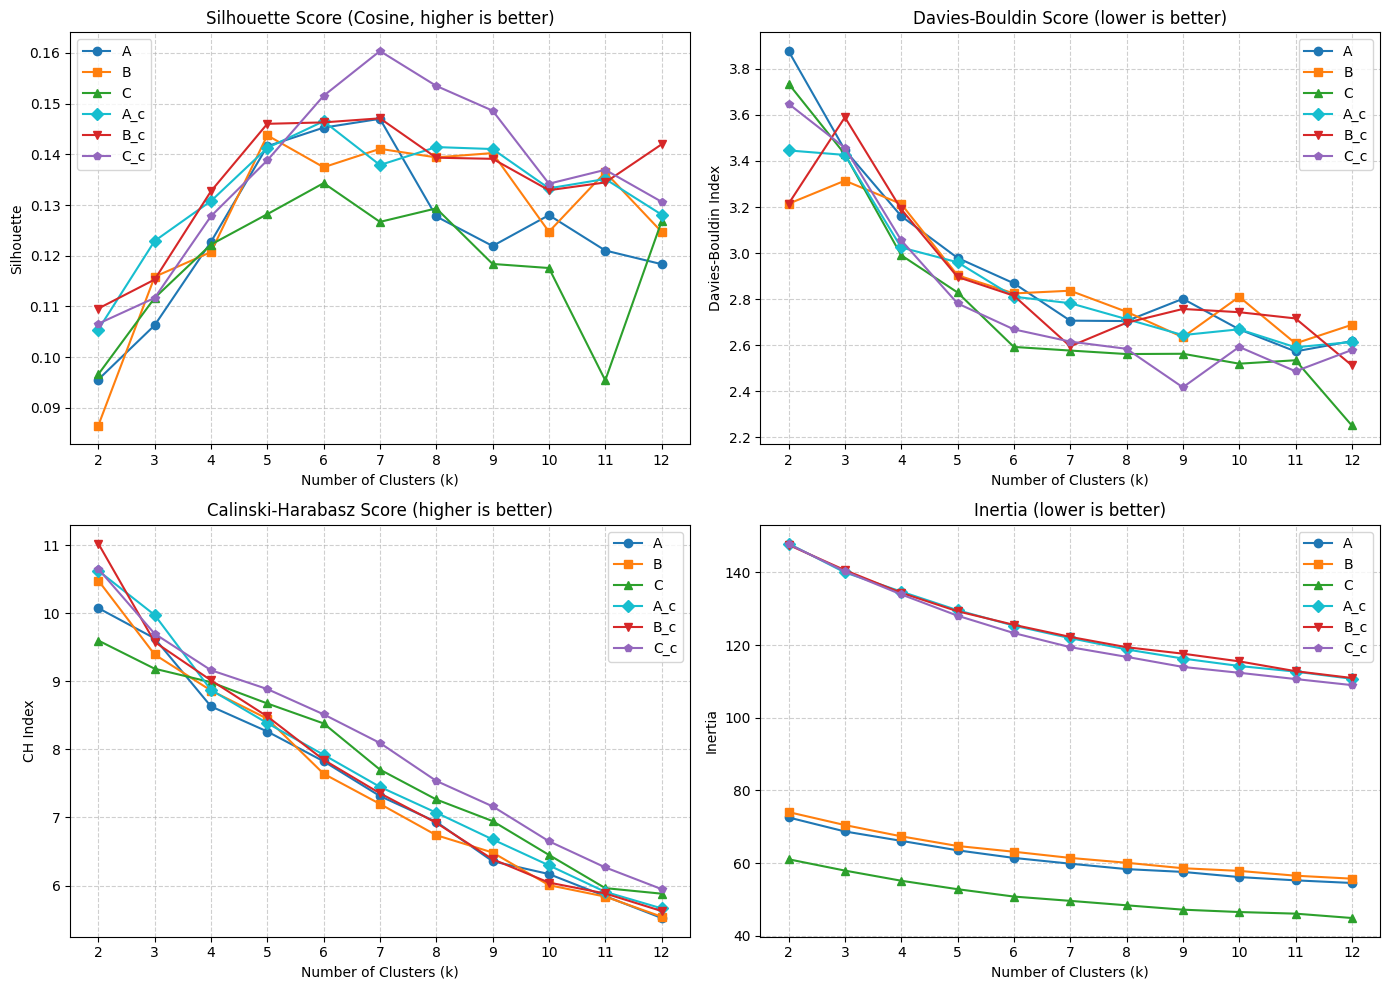

In [2]:
k_range = list(range(2, 13))

sil_dict = {v: [] for v in versions}
db_dict = {v: [] for v in versions}
ch_dict = {v: [] for v in versions}
inertia_dict = {v: [] for v in versions}
labels_k7 = {}

for v_name, emb in versions.items():
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=50, random_state=42)
        labs = km.fit_predict(emb)
        if k == 7:
            labels_k7[v_name] = labs
        sil = silhouette_score(emb, labs, metric='cosine')
        db = davies_bouldin_score(emb, labs)
        ch = calinski_harabasz_score(emb, labs)
        inertia = km.inertia_
        
        sil_dict[v_name].append(sil)
        db_dict[v_name].append(db)
        ch_dict[v_name].append(ch)
        inertia_dict[v_name].append(inertia)

df_sil = pd.DataFrame(sil_dict, index=k_range).T
df_db = pd.DataFrame(db_dict, index=k_range).T
df_ch = pd.DataFrame(ch_dict, index=k_range).T
df_inertia = pd.DataFrame(inertia_dict, index=k_range).T

print("=== SILHOUETTE SCORE (COSINE) ===")
display(df_sil.round(4))

print("\n=== DAVIES-BOULDIN SCORE ===")
display(df_db.round(4))

print("\n=== CALINSKI-HARABASZ SCORE ===")
display(df_ch.round(2))

print("\n=== INERTIA ===")
display(df_inertia.round(2))

# Plot 4 panels
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

colors = {
    'A': '#1f77b4', 'B': '#ff7f0e', 'C': '#2ca02c',
    'A_c': '#17becf', 'B_c': '#d62728', 'C_c': '#9467bd'
}
markers = {'A': 'o', 'B': 's', 'C': '^', 'A_c': 'D', 'B_c': 'v', 'C_c': 'p'}

# Panel 1: Silhouette
ax1 = axes[0, 0]
for v in versions:
    ax1.plot(k_range, df_sil.loc[v], label=v, color=colors[v], marker=markers[v])
ax1.set_title("Silhouette Score (Cosine, higher is better)")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Silhouette")
ax1.set_xticks(k_range)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Panel 2: Davies-Bouldin
ax2 = axes[0, 1]
for v in versions:
    ax2.plot(k_range, df_db.loc[v], label=v, color=colors[v], marker=markers[v])
ax2.set_title("Davies-Bouldin Score (lower is better)")
ax2.set_xlabel("Number of Clusters (k)")
ax2.set_ylabel("Davies-Bouldin Index")
ax2.set_xticks(k_range)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

# Panel 3: Calinski-Harabasz
ax3 = axes[1, 0]
for v in versions:
    ax3.plot(k_range, df_ch.loc[v], label=v, color=colors[v], marker=markers[v])
ax3.set_title("Calinski-Harabasz Score (higher is better)")
ax3.set_xlabel("Number of Clusters (k)")
ax3.set_ylabel("CH Index")
ax3.set_xticks(k_range)
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend()

# Panel 4: Inertia
ax4 = axes[1, 1]
for v in versions:
    ax4.plot(k_range, df_inertia.loc[v], label=v, color=colors[v], marker=markers[v])
ax4.set_title("Inertia (lower is better)")
ax4.set_xlabel("Number of Clusters (k)")
ax4.set_ylabel("Inertia")
ax4.set_xticks(k_range)
ax4.grid(True, linestyle='--', alpha=0.6)
ax4.legend()

plt.tight_layout()
plt.show()


## 3. Null Baseline via 50-Dimensional PCA
Project each representation to 50 principal components. Construct 30 synthetic null datasets per representation by sampling from independent Gaussians parameterized with the empirical component mean and standard deviation. Compute Euclidean silhouette in PCA space for real and synthetic data, reporting null means, standard deviations, and the count of null runs scoring at or above the empirical value.

In [3]:
null_summary_records = []

for v_name, emb in versions.items():
    pca = PCA(n_components=50, random_state=42)
    X_pca = pca.fit_transform(emb)
    means = X_pca.mean(axis=0)
    stds = X_pca.std(axis=0)
    
    # Real silhouette in PCA space
    real_sils = {}
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=50, random_state=42)
        labs = km.fit_predict(X_pca)
        real_sils[k] = silhouette_score(X_pca, labs, metric='euclidean')
        
    # 30 Null datasets
    null_sils = {k: [] for k in k_range}
    for run in range(30):
        rng = np.random.RandomState(seed=42 + run)
        X_null = rng.normal(loc=means, scale=stds, size=(158, 50))
        for k in k_range:
            km_null = KMeans(n_clusters=k, n_init=50, random_state=42)
            null_labs = km_null.fit_predict(X_null)
            null_s = silhouette_score(X_null, null_labs, metric='euclidean')
            null_sils[k].append(null_s)
            
    for k in k_range:
        r_val = real_sils[k]
        n_vals = null_sils[k]
        n_mean = np.mean(n_vals)
        n_sd = np.std(n_vals)
        n_ge = sum(nv >= r_val for nv in n_vals)
        null_summary_records.append({
            'version': v_name,
            'k': k,
            'real_sil': r_val,
            'null_mean': n_mean,
            'null_sd': n_sd,
            'null_ge_real': n_ge
        })

df_null_summary = pd.DataFrame(null_summary_records)

print("=== NULL BASELINE: REAL VS. SYNTHETIC SILHOUETTE (PCA-50) ===")
for v in versions:
    print(f"\n--- Version {v} ---")
    sub_df = df_null_summary[df_null_summary['version'] == v][['k', 'real_sil', 'null_mean', 'null_sd', 'null_ge_real']]
    display(sub_df.round(4))


=== NULL BASELINE: REAL VS. SYNTHETIC SILHOUETTE (PCA-50) ===

--- Version A ---


,k,real_sil,null_mean,null_sd,null_ge_real
0,2,0.0650,0.0620,0.0046,9
1,3,0.0738,0.0522,0.0032,0
2,4,0.0847,0.0483,0.0035,0
3,5,0.0968,0.0462,0.0032,0
4,6,0.1034,0.0431,0.0041,0
5,7,0.0877,0.0412,0.0033,0
6,8,0.0969,0.0400,0.0035,0
7,9,0.0964,0.0379,0.0033,0
8,10,0.0897,0.0370,0.0034,0
9,11,0.0979,0.0356,0.0045,0



--- Version B ---


,k,real_sil,null_mean,null_sd,null_ge_real
11,2,0.0616,0.0630,0.0048,17
12,3,0.0800,0.0533,0.0038,0
13,4,0.0847,0.0490,0.0034,0
14,5,0.0984,0.0463,0.0031,0
15,6,0.0957,0.0438,0.0037,0
16,7,0.0900,0.0412,0.0044,0
17,8,0.0931,0.0409,0.0037,0
18,9,0.0939,0.0383,0.0030,0
19,10,0.0879,0.0373,0.0053,0
20,11,0.0991,0.0362,0.0034,0



--- Version C ---


...

,k,real_sil,null_mean,null_sd,null_ge_real
33,2,0.0701,0.0638,0.0052,4
34,3,0.0818,0.0536,0.0037,0
35,4,0.0874,0.0488,0.0029,0
36,5,0.0955,0.0458,0.0030,0
37,6,0.0999,0.0441,0.0036,0
38,7,0.0974,0.0411,0.0040,0
39,8,0.1010,0.0397,0.0034,0
40,9,0.0981,0.0381,0.0030,0
41,10,0.0993,0.0370,0.0043,0
42,11,0.0933,0.0357,0.0052,0



--- Version B_c ---


,k,real_sil,null_mean,null_sd,null_ge_real
44,2,0.0744,0.0645,0.0054,1
45,3,0.0773,0.0540,0.0037,0
46,4,0.0882,0.0495,0.0028,0
47,5,0.0993,0.0465,0.0031,0
48,6,0.1039,0.0441,0.0034,0
49,7,0.1040,0.0422,0.0030,0
50,8,0.1016,0.0409,0.0032,0
51,9,0.0997,0.0382,0.0031,0
52,10,0.0970,0.0379,0.0030,0
53,11,0.0988,0.0356,0.0032,0



--- Version C_c ---


,k,real_sil,null_mean,null_sd,null_ge_real
55,2,0.0703,0.0693,0.0053,14
56,3,0.0743,0.0594,0.0038,0
57,4,0.0808,0.0549,0.0031,0
58,5,0.0948,0.0517,0.0035,0
59,6,0.1059,0.0485,0.0035,0
60,7,0.1078,0.0467,0.0042,0
61,8,0.1068,0.0446,0.0038,0
62,9,0.1005,0.0436,0.0046,0
63,10,0.0981,0.0413,0.0032,0
64,11,0.0985,0.0395,0.0044,0


## 4. Seed Stability Across 30 Random Initializations
Evaluate cluster assignment stability across 30 seeds ($0..29$) with $n_{	ext{init}}=10$ for $k \in [4, 10]$, computing mean and minimum pairwise ARI across all $inom{30}{2}=435$ seed pairs. At $k=7$, evaluate $n_{	ext{init}}=50$ across the same 30 seeds and report the count of seeds returning identical partitions to seed 0.

In [4]:
seed_k_values = [4, 5, 6, 7, 8, 9, 10]
seed_stability_records = []
k7_identical_counts = {}

for v_name, emb in versions.items():
    for k in seed_k_values:
        labs_by_seed = []
        for s in range(30):
            km = KMeans(n_clusters=k, n_init=10, random_state=s)
            labs_by_seed.append(km.fit_predict(emb))
        
        aris = [adjusted_rand_score(labs_by_seed[i], labs_by_seed[j]) for i, j in combinations(range(30), 2)]
        seed_stability_records.append({
            'version': v_name,
            'k': k,
            'mean_ari': np.mean(aris),
            'min_ari': np.min(aris)
        })
        
    # k=7 with n_init=50
    k7_50_labs = []
    for s in range(30):
        km = KMeans(n_clusters=7, n_init=50, random_state=s)
        k7_50_labs.append(km.fit_predict(emb))
    ref_partition = k7_50_labs[0]
    id_cnt = sum(np.isclose(adjusted_rand_score(ref_partition, lab), 1.0) for lab in k7_50_labs)
    k7_identical_counts[v_name] = id_cnt

df_seed_stab = pd.DataFrame(seed_stability_records)

print("=== SEED STABILITY: MEAN PAIRWISE ARI (30 SEEDS, n_init=10) ===")
display(df_seed_stab.pivot(index='version', columns='k', values='mean_ari').round(4))

print("\n=== SEED STABILITY: MINIMUM PAIRWISE ARI (30 SEEDS, n_init=10) ===")
display(df_seed_stab.pivot(index='version', columns='k', values='min_ari').round(4))

print("\n=== IDENTICAL PARTITION COUNT TO SEED 0 AT k=7 (n_init=50, 30 SEEDS) ===")
for v_name, cnt in k7_identical_counts.items():
    print(f"  Version {v_name:<5}: {cnt}/30 seeds return identical partition (ARI = 1.0)")


=== SEED STABILITY: MEAN PAIRWISE ARI (30 SEEDS, n_init=10) ===


k,4,5,6,7,8,9,10
version,,,,,,,
A,0.6832,0.7609,0.6617,0.6113,0.5890,0.5838,0.5857
A_c,0.7021,0.7449,0.7548,0.7058,0.6945,0.6578,0.6279
B,0.6985,0.7081,0.6446,0.5791,0.5825,0.5476,0.5101
B_c,0.7768,0.7909,0.7425,0.6807,0.6377,0.5954,0.5880
C,0.4714,0.5237,0.6169,0.5649,0.5461,0.5165,0.4889
C_c,0.5669,0.6802,0.7174,0.6866,0.6461,0.5872,0.5794



=== SEED STABILITY: MINIMUM PAIRWISE ARI (30 SEEDS, n_init=10) ===


k,4,5,6,7,8,9,10
version,,,,,,,
A,0.3512,0.5429,0.4040,0.4226,0.4029,0.4175,0.4468
A_c,0.4409,0.3587,0.5060,0.4734,0.5002,0.4863,0.4920
B,0.3583,0.4557,0.4117,0.3983,0.3790,0.3669,0.3482
B_c,0.3572,0.6016,0.5681,0.4661,0.4587,0.4603,0.4450
C,0.1911,0.3141,0.4008,0.3480,0.3454,0.3670,0.3103
C_c,0.2194,0.3758,0.4833,0.5095,0.4273,0.4263,0.3889



=== IDENTICAL PARTITION COUNT TO SEED 0 AT k=7 (n_init=50, 30 SEEDS) ===
  Version A    : 1/30 seeds return identical partition (ARI = 1.0)
  Version B    : 1/30 seeds return identical partition (ARI = 1.0)
  Version C    : 1/30 seeds return identical partition (ARI = 1.0)
  Version A_c  : 1/30 seeds return identical partition (ARI = 1.0)
  Version B_c  : 1/30 seeds return identical partition (ARI = 1.0)
  Version C_c  : 1/30 seeds return identical partition (ARI = 1.0)


## 5. Subsample Stability (80% Resampling Without Replacement)
Assess sensitivity to dataset composition by drawing 80% of countries (126 countries) without replacement across 30 iterations for $k \in [5, 7, 9]$. Compare subsample cluster labels ($n_{	ext{init}}=10$) against the full-dataset solution ($n_{	ext{init}}=50, 	ext{random\_state}=42$) on the overlapping subset.

In [5]:
sub_k_values = [5, 7, 9]
subsample_records = []

for v_name, emb in versions.items():
    for k in sub_k_values:
        km_full = KMeans(n_clusters=k, n_init=50, random_state=42)
        full_labs = km_full.fit_predict(emb)
        
        draw_aris = []
        for s in range(30):
            rng = np.random.RandomState(seed=s)
            sub_idx = rng.choice(158, size=126, replace=False)
            sub_emb = emb[sub_idx]
            km_sub = KMeans(n_clusters=k, n_init=10, random_state=s)
            sub_labs = km_sub.fit_predict(sub_emb)
            
            ari = adjusted_rand_score(sub_labs, full_labs[sub_idx])
            draw_aris.append(ari)
            
        subsample_records.append({
            'version': v_name,
            'k': k,
            'mean_ari': np.mean(draw_aris),
            'sd_ari': np.std(draw_aris)
        })

df_subsample_summary = pd.DataFrame(subsample_records)

print("=== SUBSAMPLE STABILITY SUMMARY (MEAN ± SD ARI) ===")
for k in sub_k_values:
    print(f"\n--- k = {k} ---")
    sub_k = df_subsample_summary[df_subsample_summary['k'] == k]
    for _, r in sub_k.iterrows():
        print(f"  Version {r['version']:<5}: {r['mean_ari']:.4f} ± {r['sd_ari']:.4f}")


=== SUBSAMPLE STABILITY SUMMARY (MEAN ± SD ARI) ===

--- k = 5 ---
  Version A    : 0.6951 ± 0.1256
  Version B    : 0.7111 ± 0.1283
  Version C    : 0.5031 ± 0.0988
  Version A_c  : 0.7295 ± 0.1040
  Version B_c  : 0.7565 ± 0.0948
  Version C_c  : 0.6436 ± 0.1062

--- k = 7 ---
  Version A    : 0.6129 ± 0.1174
  Version B    : 0.5829 ± 0.0906
  Version C    : 0.5078 ± 0.0869
  Version A_c  : 0.6721 ± 0.0840
  Version B_c  : 0.6521 ± 0.0751
  Version C_c  : 0.6909 ± 0.0786

--- k = 9 ---
  Version A    : 0.5643 ± 0.0572
  Version B    : 0.5678 ± 0.0649
  Version C    : 0.5468 ± 0.0613
  Version A_c  : 0.6559 ± 0.0578
  Version B_c  : 0.5817 ± 0.0599
  Version C_c  : 0.5967 ± 0.0629


## 6. Agreement Across Representations at $k=7$
Compute and display the $6 	imes 6$ pairwise ARI matrix across all representations clustered at $k=7$ ($n_{	ext{init}}=50, 	ext{random\_state}=42$).

In [6]:
ver_keys = ['A', 'B', 'C', 'A_c', 'B_c', 'C_c']
ari_6x6 = np.zeros((6, 6))

for i, v1 in enumerate(ver_keys):
    for j, v2 in enumerate(ver_keys):
        ari_6x6[i, j] = adjusted_rand_score(labels_k7[v1], labels_k7[v2])

df_ari_6x6 = pd.DataFrame(ari_6x6, index=ver_keys, columns=ver_keys)
print("=== 6x6 ARI AGREEMENT MATRIX AT k=7 ===")
display(df_ari_6x6.round(4))


=== 6x6 ARI AGREEMENT MATRIX AT k=7 ===


,A,B,C,A_c,B_c,C_c
A,1.0000,0.6806,0.5053,0.6579,0.6607,0.5202
B,0.6806,1.0000,0.4021,0.5898,0.6965,0.4503
C,0.5053,0.4021,1.0000,0.4242,0.4409,0.7660
A_c,0.6579,0.5898,0.4242,1.0000,0.5562,0.5236
B_c,0.6607,0.6965,0.4409,0.5562,1.0000,0.5073
C_c,0.5202,0.4503,0.7660,0.5236,0.5073,1.0000


## 7. Length Confound Diagnostics at $k=7$
Inspect word count distributions within each cluster, perform non-parametric Kruskal-Wallis tests of `extracted_words` across clusters, and calculate ARI between cluster assignments and document length terciles.

In [7]:
words = df_order['extracted_words'].values
terciles = pd.qcut(words, 3, labels=False)

print("=== LENGTH CONFOUND DIAGNOSTICS AT k=7 ===")

for v_name in ver_keys:
    labs = labels_k7[v_name]
    print(f"\n--- Version {v_name} ---")
    cluster_stats = []
    groups = []
    for c in range(7):
        c_words = words[labs == c]
        groups.append(c_words)
        cluster_stats.append({
            'cluster': c,
            'n': len(c_words),
            'median': np.median(c_words),
            'min': np.min(c_words),
            'max': np.max(c_words)
        })
    df_c_stats = pd.DataFrame(cluster_stats)
    display(df_c_stats)
    
    H, pval = kruskal(*groups)
    ari_terc = adjusted_rand_score(labs, terciles)
    print(f"  Kruskal-Wallis H: {H:.4f}, p-value: {pval:.4e}")
    print(f"  ARI with length terciles: {ari_terc:.4f}")


=== LENGTH CONFOUND DIAGNOSTICS AT k=7 ===

--- Version A ---


,cluster,n,median,min,max
0,0,27,245.0,66,2011
1,1,18,279.5,75,1160
2,2,19,151.0,68,685
3,3,38,247.0,77,835
4,4,24,127.5,33,610
5,5,17,104.0,52,464
6,6,15,548.0,101,3223


  Kruskal-Wallis H: 37.3875, p-value: 1.4796e-06
  ARI with length terciles: 0.0386

--- Version B ---


,cluster,n,median,min,max
0,0,10,446.0,120,1160
1,1,25,245.0,66,2011
2,2,33,252.0,77,835
3,3,24,132.5,33,610
4,4,34,109.0,52,580
5,5,17,494.0,165,3223
6,6,15,175.0,68,685


  Kruskal-Wallis H: 47.1837, p-value: 1.7197e-08
  ARI with length terciles: 0.0657

--- Version C ---


...

  Kruskal-Wallis H: 38.5533, p-value: 8.7552e-07
  ARI with length terciles: 0.0471

--- Version B_c ---


,cluster,n,median,min,max
0,0,18,97.5,33,344
1,1,31,118.0,59,685
2,2,36,255.0,77,835
3,3,17,548.0,165,3223
4,4,26,240.0,66,2011
5,5,17,122.0,52,580
6,6,13,434.0,120,1160


  Kruskal-Wallis H: 53.2390, p-value: 1.0502e-09
  ARI with length terciles: 0.0621

--- Version C_c ---


,cluster,n,median,min,max
0,0,17,289.0,120,1160
1,1,23,182.0,33,610
2,2,27,308.0,95,1307
3,3,17,494.0,165,3223
4,4,28,108.0,33,376
5,5,21,235.0,70,2011
6,6,25,118.0,59,685


  Kruskal-Wallis H: 61.1438, p-value: 2.6352e-11
  ARI with length terciles: 0.0800


## 8. Original Clusters Comparison and Cluster Export
Evaluate ARI against `orig_cluster` across all six versions at $k=7$. Identify the representation with the highest silhouette at $k=7$ and display its contingency crosstab against original clusters. Save the full partition assignments to `data/processed/cluster_runs.csv`.

In [8]:
orig_clusters = df_order['orig_cluster'].values

print("=== ARI AGAINST ORIGINAL CLUSTERS (k=7) ===")
orig_aris = {}
for v_name in ver_keys:
    ari_orig = adjusted_rand_score(labels_k7[v_name], orig_clusters)
    orig_aris[v_name] = ari_orig
    print(f"  Version {v_name:<5}: ARI vs orig_cluster = {ari_orig:.4f}")

# Identify version with highest silhouette at k=7
k7_sils = {v_name: df_sil.loc[v_name, 7] for v_name in ver_keys}
best_ver = max(k7_sils, key=k7_sils.get)
print(f"\nVersion with highest cosine silhouette at k=7: {best_ver} (silhouette = {k7_sils[best_ver]:.4f})")

print(f"\nCrosstab: New Clusters ({best_ver}) vs. Original Clusters:")
ct = pd.crosstab(labels_k7[best_ver], orig_clusters, rownames=[f'New Cluster ({best_ver})'], colnames=['Original Cluster'])
display(ct)

# Save cluster_runs.csv
df_runs = df_order[['Country', 'status', 'extracted_words', 'orig_cluster']].copy()
for v_name in ver_keys:
    df_runs[f'labels_{v_name}'] = labels_k7[v_name]

runs_csv_path = os.path.join(data_dir, 'cluster_runs.csv')
df_runs.to_csv(runs_csv_path, index=False)
print(f"\nSaved cluster runs to: {runs_csv_path}")
print(f"Shape: {df_runs.shape}")
print(f"\nFirst 5 rows:")
display(df_runs.head(5))


=== ARI AGAINST ORIGINAL CLUSTERS (k=7) ===
  Version A    : ARI vs orig_cluster = 0.7117
  Version B    : ARI vs orig_cluster = 0.5867
  Version C    : ARI vs orig_cluster = 0.4386
  Version A_c  : ARI vs orig_cluster = 0.5537
  Version B_c  : ARI vs orig_cluster = 0.6547
  Version C_c  : ARI vs orig_cluster = 0.4758

Version with highest cosine silhouette at k=7: C_c (silhouette = 0.1604)

Crosstab: New Clusters (C_c) vs. Original Clusters:


Original Cluster,0,1,2,3,4,5,6
New Cluster (C_c),,,,,,,
0,0,0,1,13,2,0,1
1,17,1,0,1,4,0,0
2,0,0,1,0,1,0,25
3,0,0,15,2,0,0,0
4,6,5,0,3,4,0,10
5,2,0,0,0,19,0,0
6,0,10,0,1,0,14,0



Saved cluster runs to: ../data/processed/cluster_runs.csv
Shape: (158, 10)

First 5 rows:


,Country,status,extracted_words,orig_cluster,labels_A,labels_B,labels_C,labels_A_c,labels_B_c,labels_C_c
0,Afghanistan,preamble_ok,255,2,5,4,4,6,1,3
1,Albania,preamble_ok,114,1,2,4,5,0,1,6
2,Algeria,preamble_ok,1307,2,6,5,4,1,3,2
3,Andorra,preamble_ok,255,5,2,6,1,0,1,6
4,Angola,preamble_ok,580,4,3,4,2,1,5,2
